# Approximate sufficiency: logistic regression with offsets

Logistic regression with a per-observation offset is a standard case where exact compression fails. This is the
finishing-skill problem from the [football factor model](https://nathanielf.github.io/football_models_with_wyatt/).
Each shot $i$ has a pre-shot goal probability $p_i$ from an expected-goals (xG) model. A player's finishing skill
$\eta$ shifts the log-odds of every shot:

$$\Pr(\text{goal}_i) = \operatorname{logit}^{-1}(\operatorname{logit} p_i + \eta).$$

Goals $G = \sum_i y_i$ are exactly sufficient for $\eta$ (a canonical-link GLM always has a sufficient statistic
for the outcome). But the log-likelihood's normalising term $\sum_i \log(1 + e^{\operatorname{logit} p_i + \eta})$
runs over every shot, so evaluating it still needs every row.

Expanding the log-likelihood to second order around $\eta = 0$ gives

$$\ell(\eta) \approx \ell(0) + (G - X)\,\eta - \tfrac12 V \eta^2, \qquad G=\sum_i y_i,\; X=\sum_i p_i,\; V=\sum_i p_i(1-p_i):$$

goals, expected goals, and the Bernoulli variance of expected goals. Completing the square shows this is the
log-likelihood of a Gaussian pseudo-observation,

$$\hat\eta = \frac{G - X}{V} \;\sim\; \mathcal N\!\left(\eta,\ \text{sd} = 1/\sqrt V\right),$$

which can be fitted with an ordinary `pm.Normal`. It keeps a pointwise log-likelihood, which a `pm.Potential`
would not.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
from scipy.special import expit, logit

rng = np.random.default_rng(606)
SAMPLE_KW = dict(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=False)
TIMINGS = []


def timed_fit(model, label, n_rows, case, kind, **kw):
    t0 = time.perf_counter()
    idata = pm.sample(model=model, random_seed=rng, **{**SAMPLE_KW, **kw})
    secs = time.perf_counter() - t0
    ess = float(az.summary(idata)["ess_bulk"].min())
    TIMINGS.append({"case": case, "kind": kind, "model": label, "rows": int(n_rows),
                    "wall_s": round(secs, 2), "min_ess_per_s": round(ess / secs, 1),
                    "divergences": int(idata.sample_stats["diverging"].sum())})
    return idata


def save_timings(name):
    Path("timings").mkdir(exist_ok=True)
    Path(f"timings/{name}.json").write_text(json.dumps(TIMINGS, indent=1))
    return pd.DataFrame(TIMINGS).drop(columns="case")

## Shots, players, and how good the quadratic is

A simulator: `n_players` players, each taking 30 to 300 shots with skewed xG (mostly low-quality chances), and a
true finishing skill drawn with standard deviation `tau` on the log-odds scale.

In [2]:
def simulate(n_players, tau):
    eta = rng.normal(0, tau, n_players)
    n_shots = rng.integers(30, 300, n_players)
    player = np.repeat(np.arange(n_players), n_shots)
    xg = rng.beta(0.6, 4.2, len(player))
    goal = rng.binomial(1, expit(logit(xg) + eta[player]))
    return eta, pd.DataFrame({"player": player, "xg": xg, "goal": goal})


def summarise(shots, eta0=None):
    """(G, X, V) per player, optionally expanded around a player-specific point eta0."""
    off = logit(shots.xg.values) + (0 if eta0 is None else eta0[shots.player.values])
    q = expit(off)
    g = pd.DataFrame({"player": shots.player, "G": shots.goal, "X": q, "V": q * (1 - q), "shots": 1})
    return g.groupby("player").sum()

The figure compares the exact log-likelihood with the quadratic for three simulated players with zero skill and
different numbers of shots. Each curve peaks away from zero because of chance; players with fewer shots have
flatter curves that peak further away. The quadratic matches the exact curve closely within about 0.3 log-odds
units of zero, which covers realistic finishing effects.

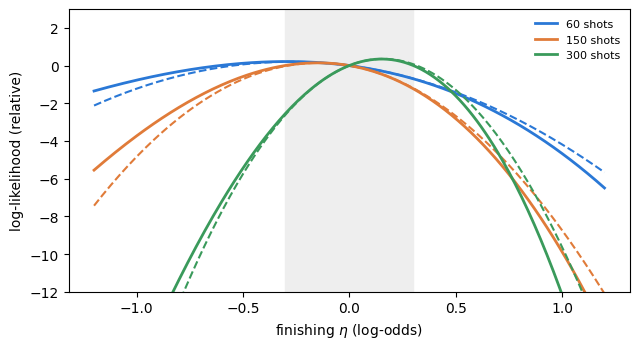

In [3]:
#| label: fig-approx-curve
#| fig-cap: "Exact shot-by-shot log-likelihood (solid) and the three-number quadratic (dashed) for three players with true skill 0 and different shot counts, each relative to its value at 0. The shaded range is ±0.3 log-odds."
grid = np.linspace(-1.2, 1.2, 241)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.axvspan(-0.3, 0.3, color="#eeeeee")
for n_sh, col in zip([60, 150, 300], ["#2a78d6", "#e07b39", "#3a9a5b"]):
    xg = rng.beta(0.6, 4.2, n_sh)
    goal = rng.binomial(1, xg)
    exact = np.array([(goal * (logit(xg) + e) - np.log1p(np.exp(logit(xg) + e))).sum() for e in grid])
    exact -= exact[120]
    G, Xs, V = goal.sum(), xg.sum(), (xg * (1 - xg)).sum()
    ax.plot(grid, exact, color=col, lw=2, label=f"{n_sh} shots")
    ax.plot(grid, (G - Xs) * grid - 0.5 * V * grid**2, color=col, lw=1.5, ls="--")
ax.set_ylim(-12, 3)
ax.set_xlabel(r"finishing $\eta$ (log-odds)")
ax.set_ylabel("log-likelihood (relative)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## Hierarchical finishing model: every shot vs three numbers per player

Two settings. In the realistic one, skill has standard deviation $\tau = 0.15$: a player two standard deviations
above average has about 1.8 times the odds of scoring a given chance as one two standard deviations below. In
the stress test, $\tau = 0.8$, which makes that odds ratio about 25. This is far outside the range where a
quadratic around zero should be trusted. For the stress test we also expand each player around a crude estimate
of their own skill, $\eta_0 = (G - X)/V$ (one Newton step from zero), which needs one more pass over the shots.

Both models use a non-centred parameterisation, $\eta = \tau z$ with $z \sim \mathcal N(0, 1)$, which samples
better than $\eta \sim \mathcal N(0, \tau)$ when the data per player are weak relative to $\tau$.

In [4]:
def model_full(shots, n_players):
    with pm.Model() as m:
        tau = pm.HalfNormal("tau", 0.5)
        z = pm.Normal("z", 0, 1, shape=n_players)
        eta = pm.Deterministic("eta", tau * z)
        pm.Bernoulli("goal", logit_p=logit(shots.xg.values) + eta[shots.player.values], observed=shots.goal.values)
    return m


def model_suff(summ, n_players, eta0=None):
    eta0 = np.zeros(n_players) if eta0 is None else eta0
    with pm.Model() as m:
        tau = pm.HalfNormal("tau", 0.5)
        z = pm.Normal("z", 0, 1, shape=n_players)
        eta = pm.Deterministic("eta", tau * z)
        pm.Normal("eta_hat", mu=eta, sigma=1 / np.sqrt(summ.V.values),
                  observed=eta0 + (summ.G.values - summ.X.values) / summ.V.values)
    return m


results = {}
n_players = 400
for world, tau_true in [("realistic", 0.15), ("stress", 0.8)]:
    eta_true, shots = simulate(n_players, tau_true)
    s0 = summarise(shots)
    case = "Logistic with offsets" if world == "realistic" else "Logistic with offsets (stress test)"
    fits = {"every shot": timed_fit(model_full(shots, n_players), f"{world}: Bernoulli per shot", len(shots), case, "raw"),
            "(G, X, V) at 0": timed_fit(model_suff(s0, n_players), f"{world}: (G, X, V) around 0", n_players, case, "compressed")}
    if world == "stress":
        eta0 = np.clip((s0.G - s0.X) / s0.V, -2, 2).values
        s1 = summarise(shots, eta0)
        fits["(G, X, V) at η0"] = timed_fit(model_suff(s1, n_players, eta0), f"{world}: (G, X, V) around η0",
                                            n_players, case, "compressed (re-centred)")
    results[world] = dict(eta=eta_true, shots=shots, summ=s0, fits=fits)

NUTS[nutpie]: [tau, z]
NUTS[nutpie]: [tau, z]
NUTS[nutpie]: [tau, z]
NUTS[nutpie]: [tau, z]
NUTS[nutpie]: [tau, z]


## What the model is for: shrinkage

The obvious estimate of a player's finishing skill is goals minus expected goals, scaled here as
$(G - X)/V$ to put it on the log-odds scale. For players with few shots it is noisy. The hierarchical model pulls
each player's estimate toward zero in proportion to how little data they have. The figure shows this in the
realistic setting, where the true skills are known.

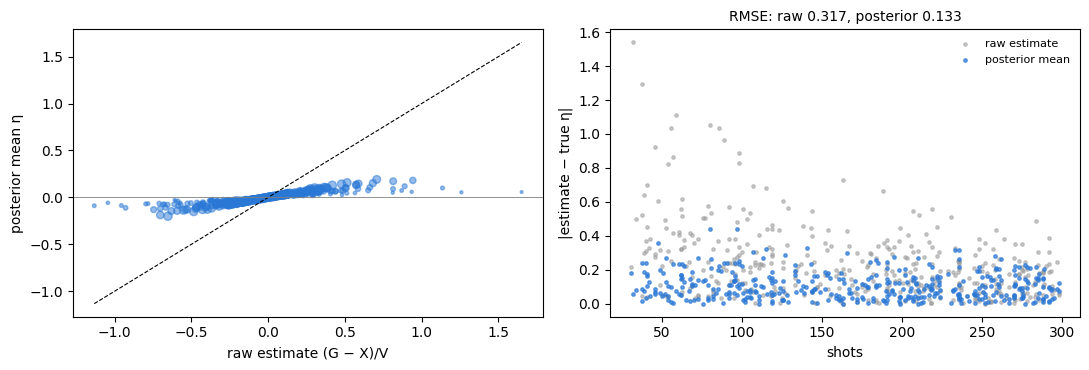

In [5]:
#| label: fig-approx-use
#| fig-cap: "Realistic setting (τ = 0.15). Left: raw estimate (G − X)/V against the posterior mean from the three-number model, sized by shots; the dashed line is no shrinkage. Right: absolute error against the true skill for the raw estimate and the posterior mean, by number of shots."
R = results["realistic"]
raw_est = ((R["summ"].G - R["summ"].X) / R["summ"].V).values
post_mean = R["fits"]["(G, X, V) at 0"].posterior["eta"].mean(("chain", "draw")).values
shots_n = R["summ"].shots.values
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.scatter(raw_est, post_mean, s=shots_n / 8, alpha=0.5, color="#2a78d6")
lim = np.array([raw_est.min(), raw_est.max()])
ax.plot(lim, lim, "k--", lw=0.8)
ax.axhline(0, color="grey", lw=0.6)
ax.set_xlabel("raw estimate (G − X)/V")
ax.set_ylabel("posterior mean η")
ax = axes[1]
ax.scatter(shots_n, np.abs(raw_est - R["eta"]), s=6, alpha=0.5, color="#999999", label="raw estimate")
ax.scatter(shots_n, np.abs(post_mean - R["eta"]), s=6, alpha=0.7, color="#2a78d6", label="posterior mean")
rmse = lambda e: np.sqrt(np.mean((e - R["eta"]) ** 2))
ax.set_title(f"RMSE: raw {rmse(raw_est):.3f}, posterior {rmse(post_mean):.3f}", fontsize=10)
ax.set_xlabel("shots")
ax.set_ylabel("|estimate − true η|")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

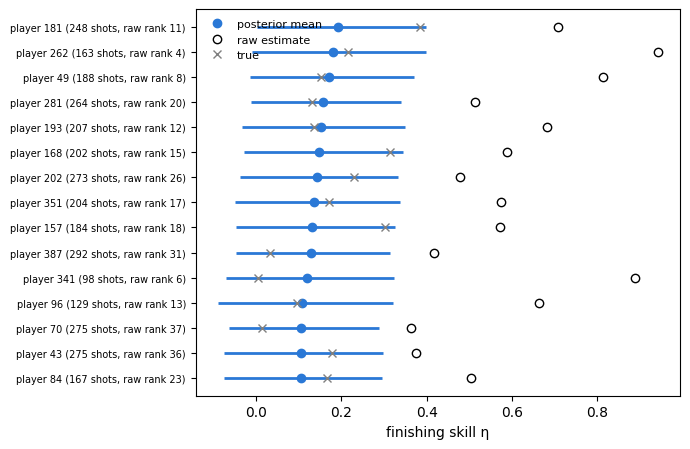

In [6]:
#| label: fig-approx-board
#| fig-cap: "Realistic setting: the 15 players with the highest posterior mean skill, with 89% intervals, the raw estimate (open circle) and the true skill (grey cross). Labels give shots taken and the player's rank by raw estimate."
eta_draws = R["fits"]["(G, X, V) at 0"].posterior["eta"].values.reshape(-1, n_players)
top = np.argsort(-post_mean)[:15]
raw_rank = (-raw_est).argsort().argsort() + 1
lo, hi = np.quantile(eta_draws[:, top], [0.055, 0.945], 0)
fig, ax = plt.subplots(figsize=(7, 4.6))
yy = np.arange(15)[::-1]
ax.hlines(yy, lo, hi, color="#2a78d6", lw=2)
ax.plot(post_mean[top], yy, "o", color="#2a78d6", label="posterior mean")
ax.plot(raw_est[top], yy, "o", mfc="none", color="k", label="raw estimate")
ax.plot(R["eta"][top], yy, "x", color="grey", label="true")
ax.set_yticks(yy, [f"player {p} ({shots_n[p]} shots, raw rank {raw_rank[p]})" for p in top], fontsize=7)
ax.set_xlabel("finishing skill η")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## Every shot vs three numbers

In the realistic setting the two fits agree player by player. In the stress test, the expansion around zero
overstates skill at both ends: the best players come out better and the worst players worse than the exact fit.
The quadratic misplaces the curvature of the likelihood far from zero. Re-centring each player's expansion on
their own crude estimate removes the error.

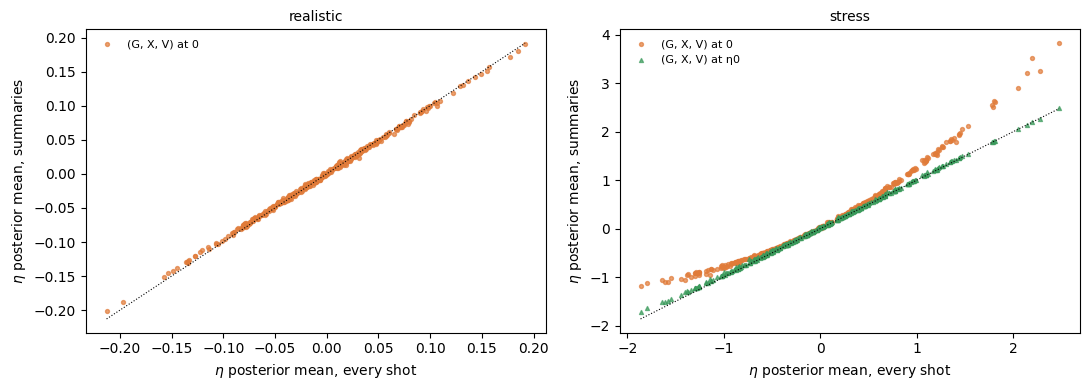

In [7]:
#| label: fig-approx-equiv
#| fig-cap: "Posterior mean finishing skill per player from the summaries against the exact shot-level fit. Left: realistic spread; the points lie on the diagonal. Right: the stress test; expanding around zero overstates both tails, re-centring on a one-step estimate removes the error."
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
styles = {"(G, X, V) at 0": dict(color="#e07b39", s=8), "(G, X, V) at η0": dict(color="#3a9a5b", s=8, marker="^")}
for ax, world in zip(axes, ["realistic", "stress"]):
    fits = results[world]["fits"]
    ref = fits["every shot"].posterior["eta"].mean(("chain", "draw")).values
    for k, st in styles.items():
        if k in fits:
            ax.scatter(ref, fits[k].posterior["eta"].mean(("chain", "draw")).values, label=k, alpha=0.7, **st)
    lim = [ref.min(), ref.max()]
    ax.plot(lim, lim, "k:", lw=0.8)
    ax.set_title(world, fontsize=10)
    ax.set_xlabel(r"$\eta$ posterior mean, every shot")
    ax.set_ylabel(r"$\eta$ posterior mean, summaries")
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
#| label: tbl-approx-speed
#| tbl-cap: "Shot-level vs three-numbers-per-player fits, with divergences and the population spread τ each recovers."
speed = save_timings("06_approximate_sufficiency")
speed["tau mean"] = [float(f.posterior["tau"].mean()) for w in results for f in results[w]["fits"].values()]
speed.round(3)

,kind,model,rows,wall_s,min_ess_per_s,divergences,tau mean
0,raw,realistic: Bernoulli per shot,68675,61.19,23.4,0,0.133
1,compressed,"realistic: (G, X, V) around 0",400,1.01,1341.6,0,0.131
2,raw,stress: Bernoulli per shot,63867,58.97,12.0,0,0.823
3,compressed,"stress: (G, X, V) around 0",400,1.21,743.6,0,0.903
4,compressed (re-centred),"stress: (G, X, V) around η0",400,0.82,852.7,0,0.810


## What compression gives up

- The summaries are a **Gaussian approximation to each player's likelihood**, computed once. The hierarchy and the
  priors stay exact; only the per-player likelihood is approximated. Meta-analysis uses the same structure: each
  unit contributes an estimate and a standard error, as in the eight-schools example.
- The error comes from the cubic and higher terms of the expansion, which grow with $|\eta - \eta_0|^3$. Small
  effects, or an expansion point near each player's skill, make it negligible.
- Re-centring needs one more pass over the raw data, so it suits summaries built in a pipeline that can be re-run.
- Unlike the exact cases, these summaries **only add up across shots expanded around the same point**. $(G, X, V)$
  from two seasons can be summed only if both were expanded around the same $\eta_0$.